# Day 4: Time-Series Preparation, Stationarity & Decomposition

Alright, Day 4! We've segmented our customers, but now we need to predict the future. Specifically, we need to forecast daily sales.

Before we throw data into Prophet or an LSTM neural network, we have to prep it properly. Time-series data is notoriously picky. 
Today's agenda:
1. **Aggregate & Resample:** Ensure we have a continuous daily timeline with no gaps.
2. **Stationarity Testing:** Run the Augmented Dickey-Fuller (ADF) test to check if our statistical properties are constant over time.
3. **Decomposition:** Break the time series down into Trend, Seasonality, and Residuals so we can actually *see* the underlying patterns.

Let's load up our cleaned transactions and get to work.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# Load the cleaned transactions from Day 2
print("Loading cleaned transaction data...")
transactions = pd.read_csv('data/transactions_cleaned.csv', parse_dates=['date'])

print(f"Loaded {len(transactions)} transactions.")

Loading cleaned transaction data...
Loaded 62611 transactions.


### Step 1: Aggregation & Resampling (Fixing the Timeline)

Machine learning models for time-series (especially LSTMs) expect a perfectly continuous timeline. If our dataset is missing a Tuesday because the store was closed, or if we have multiple entries per day, the models will get confused.

Let's aggregate the total sales per day, and then "resample" the data to ensure every single day from our start date to our end date exists. If a day is missing, we'll fill it with 0 sales.

Timeline created! We now have 541 continuous days of data.


,total_amount,total_quantity
date,,
2025-01-01,31199.16,135
2025-01-02,42377.80,146
2025-01-03,38068.35,138
2025-01-04,49290.46,183
2025-01-05,36620.54,136


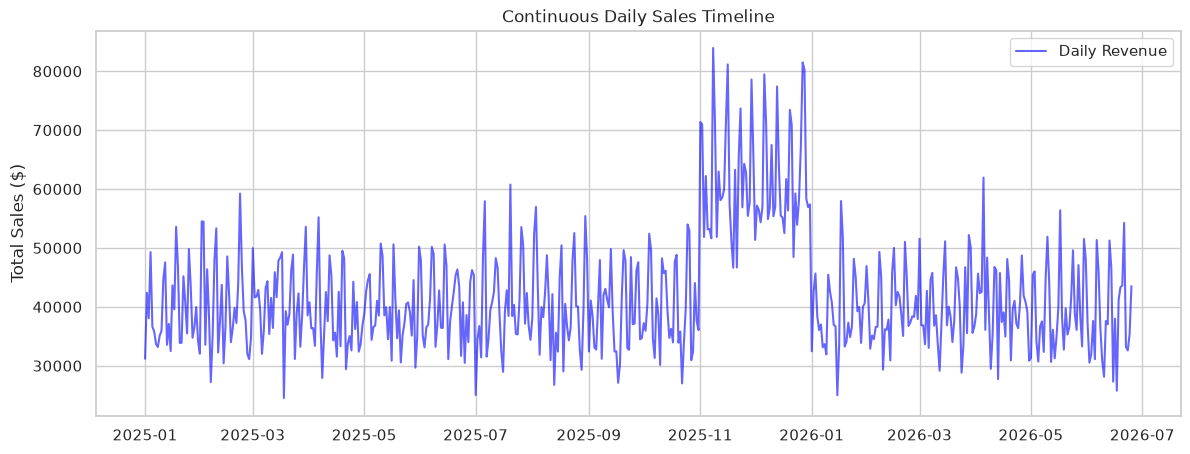

In [2]:
# 1. Aggregate total sales by day
daily_sales = transactions.groupby('date')['total_amount'].sum().reset_index()

# 2. Set the date as the index (required for time-series resampling)
daily_sales.set_index('date', inplace=True)

# 3. Resample to Daily frequency ('D') and fill missing days with 0
# This guarantees a continuous, unbroken timeline
daily_sales = daily_sales.resample('D').sum().fillna(0)

# Let's also add a column for total quantity sold, as forecasting quantity is often easier than forecasting raw dollar amounts
daily_qty = transactions.groupby('date')['quantity'].sum().resample('D').sum().fillna(0)
daily_sales['total_quantity'] = daily_qty

print(f"Timeline created! We now have {len(daily_sales)} continuous days of data.")
display(daily_sales.head())

# Quick visual check
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales['total_amount'], color='blue', alpha=0.6, label='Daily Revenue')
plt.title('Continuous Daily Sales Timeline')
plt.ylabel('Total Sales ($)')
plt.legend()
plt.show()

### Step 2: Stationarity Testing (The Augmented Dickey-Fuller Test)

In statistics, a "stationary" time series is one whose properties (like mean and variance) don't change over time. Many forecasting models (like ARIMA) *require* stationary data. 

While Prophet and LSTM are smart enough to handle non-stationary data (like our upward sales trend), it is still an industry best practice to test for it. We use the **Augmented Dickey-Fuller (ADF) test**.

- **Null Hypothesis:** The data is NOT stationary (it has a trend/unit root).
- **Alternative Hypothesis:** The data IS stationary.
- **Rule of thumb:** If the p-value is < 0.05, we reject the null hypothesis and conclude the data is stationary.

In [3]:
print("Running Augmented Dickey-Fuller (ADF) Test on Daily Revenue...\n")

# Run the ADF test
adf_result = adfuller(daily_sales['total_amount'])

# Extract the results
adf_statistic = adf_result[0]
p_value = adf_result[1]
critical_values = adf_result[4]

print(f'ADF Statistic: {adf_statistic:.4f}')
print(f'p-value: {p_value:.4f}')
print('\nCritical Values:')
for key, value in critical_values.items():
    print(f'   {key}: {value:.4f}')

print("\n--- Interpretation ---")
if p_value < 0.05:
    print("✅ p-value < 0.05. The time series is STATIONARY.")
else:
    print("⚠️ p-value >= 0.05. The time series is NON-STATIONARY (it has a trend).")
    print("   (Don't worry! Prophet and LSTM can handle this, but we will difference the data if we use ARIMA later.)")

Running Augmented Dickey-Fuller (ADF) Test on Daily Revenue...

ADF Statistic: -2.6342
p-value: 0.0861

Critical Values:
   1%: -3.4429
   5%: -2.8671
   10%: -2.5697

--- Interpretation ---
⚠️ p-value >= 0.05. The time series is NON-STATIONARY (it has a trend).
   (Don't worry! Prophet and LSTM can handle this, but we will difference the data if we use ARIMA later.)


### Step 3: Time-Series Decomposition

This is one of my favorite parts of EDA. Decomposition allows us to strip away the layers of our data to see what's really driving sales. 

We are going to break the data down into three parts:
1. **Trend:** The long-term upward or downward movement.
2. **Seasonality:** The repeating short-term cycles (e.g., weekly spikes on weekends).
3. **Residual (Noise):** The random, unpredictable variations left over.

Since we have daily data, let's look at a **weekly seasonality** (period=7).

Decomposing time series (Weekly Seasonality)...


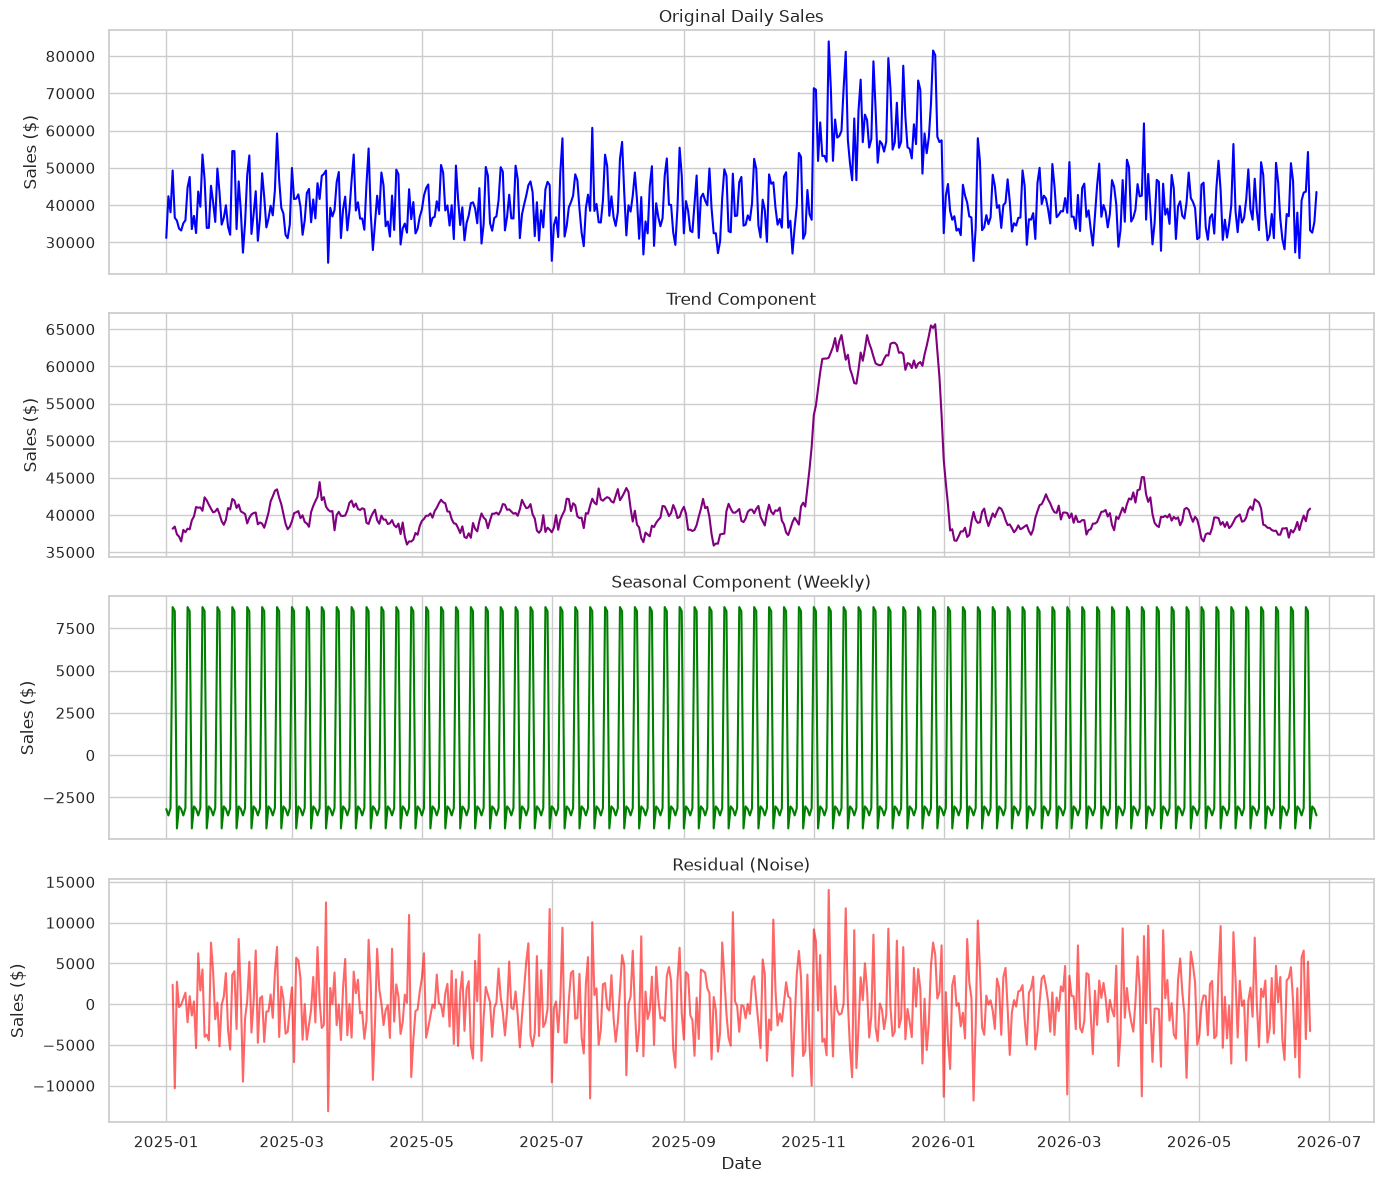

In [4]:
print("Decomposing time series (Weekly Seasonality)...")

# We use an additive model because the seasonality doesn't seem to grow proportionally with the trend
# period=7 means we are looking for a 7-day (weekly) cycle
decomposition = seasonal_decompose(daily_sales['total_amount'], model='additive', period=7)

# Plot the components
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

# Original
axes[0].plot(daily_sales.index, daily_sales['total_amount'], color='blue')
axes[0].set_title('Original Daily Sales')
axes[0].set_ylabel('Sales ($)')

# Trend
axes[1].plot(decomposition.trend.index, decomposition.trend, color='purple')
axes[1].set_title('Trend Component')
axes[1].set_ylabel('Sales ($)')

# Seasonality
axes[2].plot(decomposition.seasonal.index, decomposition.seasonal, color='green')
axes[2].set_title('Seasonal Component (Weekly)')
axes[2].set_ylabel('Sales ($)')

# Residual
axes[3].plot(decomposition.resid.index, decomposition.resid, color='red', alpha=0.6)
axes[3].set_title('Residual (Noise)')
axes[3].set_ylabel('Sales ($)')
axes[3].set_xlabel('Date')

plt.tight_layout()
plt.show()

### Wrap Up & Saving

Look at that Seasonality chart! You can clearly see the 7-day wave (spikes on weekends, dips on weekdays). The Trend chart shows our overall growth. 

Our data is now perfectly structured, tested, and understood. Tomorrow, we feed this exact dataframe into Facebook Prophet to build our baseline forecast.

Let's save this prepared time-series dataframe.

In [5]:
# Save the prepared time-series data
# We reset the index so 'date' becomes a normal column again for easier loading tomorrow
daily_sales_reset = daily_sales.reset_index()
daily_sales_reset.to_csv('data/daily_sales_prepared.csv', index=False)

print("✅ Prepared time-series data saved to data/daily_sales_prepared.csv")
print("🚀 Day 4 Complete! Tomorrow we build our Baseline Prophet Forecasting Model.")

✅ Prepared time-series data saved to data/daily_sales_prepared.csv
🚀 Day 4 Complete! Tomorrow we build our Baseline Prophet Forecasting Model.
